In [25]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [26]:
# 도미 - 35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어 - 14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]


In [27]:
# 데이터 전처리
total_length = bream_length+smelt_length
total_weight = bream_weight+smelt_weight
# label = [1]*35+[0]*14
label = ['도미']*35 + ['빙어']*14
# data = [[l,w] for l,w in zip(total_length,total_weight)] 
# data2 = np.array(data)
data = np.column_stack((total_length,total_weight))

In [ ]:
# 정규화 작업 - 수동
# 표준점수 = (특성값 - 산술평균) / 표준편차
mean = np.mean(data,axis=0) # 행의 기준으로 산술평균
std = np.std(data,axis=0) # 행의 기준으로 표준편차
train_scaled = (data-mean) / std

In [29]:
# 정규화 작업 - 자동
ss = StandardScaler()              # 정과화 선언
ss.fit(data)                       # 정규화 학습
train_scaled = ss.transform(data)  # 정규화 변환

In [30]:
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(train_scaled,label)

In [31]:
# 데이터 학습, 데이터 예측, 정학도
clf = KNeighborsClassifier()
clf.fit(train_data,train_label)
result = clf.predict(test_data) 
score = clf.score(test_data,test_label)           # 테스트데이터를 가지고 어느정도 정답을 맞췄는지 확인
# score = metrics.accuracy_score(result,test_label) # 예측되어서 나온 값과 실제정답과 비교
print("정확도 : ",score)

정확도 :  1.0


In [15]:
input1 = '25,120'
input1 = input1.split(',')
input1
input2 = list(map(float,input1))
input2

[25.0, 120.0]

In [17]:
## input받아서 도미인지, 빙어인지 확인하시오.
## 길이,무게 
input1 = input('생선의 길이와 무게를 입력하시오. (예: 25,120)')
input1 = input1.split(',')
input1
input2 = list(map(float,input1))
input2
new_input = (input2-mean)/std
result2 = clf.predict([new_input]) 
print("예측 생선 : ",result2)

예측 생선 :  ['도미']


In [9]:
distances,indexes = clf.kneighbors([new_input]) # 도미로 판다하게 된 데이터가 어떤것인지 알려줌

In [10]:
indexes

array([[23, 28, 10, 22, 27]])

In [15]:
train_scaled[0] # 정규화작업

array([-0.16326134, -0.62350364])

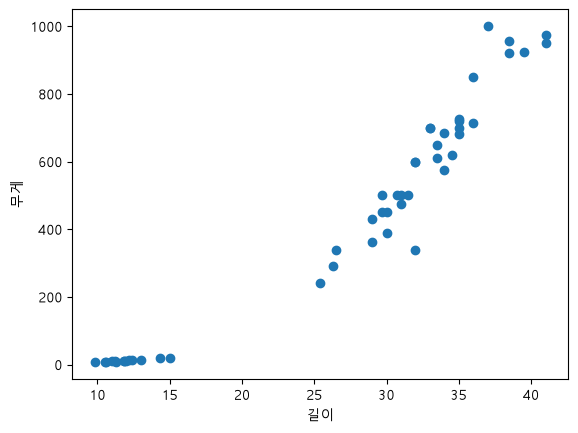

In [16]:
# 그래프 출력
plt.scatter(data[:,0],data[:,1])
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

[ 머신러닝, 확인사항]
1. 데이터 전처리 - null처리
2. 정규화 작업
3. 학습 데이터, 테스트 데이터 분리
4. 데이터 학습, 데이터 예측, 정확도
5. 산점도 그래프

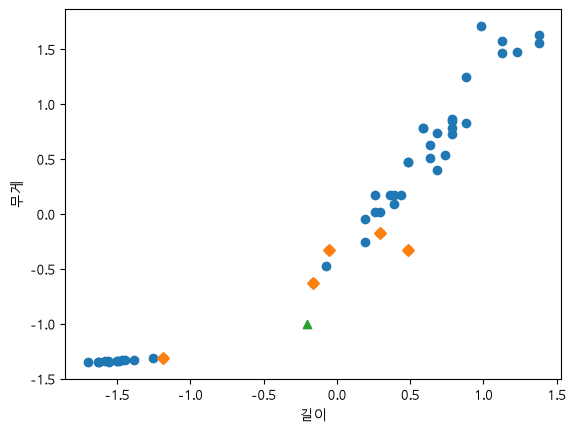

In [22]:
# 그래프 출력
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(train_data[indexes,0],train_data[indexes,1],marker='D')
plt.scatter(new_input[0],new_input[1],marker='^')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()